In [3]:
import os
import requests

from langchain.agents import create_agent
from langchain.tools import tool
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="anthropic/claude-sonnet-4.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.environ["OPENROUTER_API_KEY"]
)

@tool
def get_weather(city: str) -> str:
    """Get current weather for a city."""
    geo = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={"name": city, "count": 1},
        timeout=10,
    ).json()

    if not geo.get("results"):
        return f"Could not find city: {city}"

    place = geo["results"][0]
    wx = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={
            "latitude": place["latitude"],
            "longitude": place["longitude"],
            "current": "temperature_2m,wind_speed_10m",
        },
        timeout=10,
    ).json()

    cur = wx["current"]
    return f"{place['name']}, {place.get('country', '')}: {cur['temperature_2m']}°C, wind {cur['wind_speed_10m']} km/h"

agent = create_agent(llm, tools=[get_weather])

result = agent.invoke(
    {"messages": [{"role":"user", "content":"Is it warmer in paris or Delhi right now ?"}]},
    config={"recursion_limit": 10}
)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Is it warmer in paris or Delhi right now ?
================================== Ai Message ==================================

I'll check the current weather in both Paris and Delhi for you.
Tool Calls:
  get_weather (toolu_01YFKQ4uUbRjBavFcmHcxi3C)
 Call ID: toolu_01YFKQ4uUbRjBavFcmHcxi3C
  Args:
    city: Paris
  get_weather (toolu_017fjGnbrsFzi4NqKSz34fiL)
 Call ID: toolu_017fjGnbrsFzi4NqKSz34fiL
  Args:
    city: Delhi
================================= Tool Message =================================
Name: get_weather

Paris, France: 9.8°C, wind 10.0 km/h
================================= Tool Message =================================
Name: get_weather

Delhi, India: 25.1°C, wind 3.6 km/h
================================== Ai Message ==================================

Delhi is significantly warmer right now at **25.1°C**, compared to Paris which is at **9.8°C**. Delhi is about 15 degrees Celsius warmer t

In [4]:
from typing import Annotated, TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages] # a reducer. returns are appended.

llm_with_tools = llm.bind_tools([get_weather]) # attaches tool scheme to every llm call.

def call_model(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("model", call_model)
builder.add_node("tools", ToolNode([get_weather])) 
#ToolNode - runs every tool call in last AI message, Wraps each result in ToolMessage with right tool_call_id

builder.add_edge(START, "model")
builder.add_conditional_edges("model", tools_condition) 
# tools_condition is the router. # retruns tools if last message has tool calls.
builder.add_edge("tools", "model")
graph = builder.compile()

result = graph.invoke(
    {"messages":[{"role":"user", "content":"Is it warmer in paris or Delhi right now"}]},
    config={"recursion_limit":10}
)

for m in result["messages"]:
    m.pretty_print()

print(graph.get_graph().draw_mermaid())

================================ Human Message =================================

Is it warmer in paris or Delhi right now
================================== Ai Message ==================================

I'll check the current weather in both Paris and Delhi for you.
Tool Calls:
  get_weather (toolu_01FVkZgpoei4gsq8mpGynWkc)
 Call ID: toolu_01FVkZgpoei4gsq8mpGynWkc
  Args:
    city: Paris
  get_weather (toolu_01Rwd9v7LD2swkySHaEj786D)
 Call ID: toolu_01Rwd9v7LD2swkySHaEj786D
  Args:
    city: Delhi
================================= Tool Message =================================
Name: get_weather

Paris, France: 9.8°C, wind 10.0 km/h
================================= Tool Message =================================
Name: get_weather

Delhi, India: 25.1°C, wind 3.6 km/h
================================== Ai Message ==================================

Delhi is warmer right now. The current temperature in Delhi is 25.1°C, while Paris is at 9.8°C - making Delhi about 15 degrees Celsius warme

In [5]:
import sqlite3

conn = sqlite3.connect(":memory:", check_same_thread=False)
conn.executescript("""
CREATE TABLE customers (id INTEGER PRIMARY KEY, name TEXT, city TEXT);
CREATE TABLE orders (id INTEGER PRIMARY KEY, customer_id INTEGER, amount REAL, status TEXT);
INSERT INTO customers VALUES (1,'Asha','Delhi'),(2,'Ben','Paris'),(3,'Chen','Delhi');
INSERT INTO orders VALUES (1,1,120,'paid'),(2,1,80,'refunded'),(3,2,200,'paid'),(4,3,50,'paid');
""")

# 
@tool
def get_schema() -> str:
    """Return the CREATE statements for all tables in the database."""
    rows = conn.execute("SELECT sql FROM sqlite_master WHERE type='table'").fetchall()
    return "\n".join(r[0] for r in rows)

# get_schema exists because the model can't guess table or column names. 
# It calls it first, then writes SQL from the real schema.
@tool
def run_sql(query: str) -> str:
    """Run a read-only SQLite SELECT query and return up to 20 rows. Call get_schema first."""
    if not query.strip().lower().startswith("select"):
        return "Error: only SELECT queries are allowed."
    try:
        cur = conn.execute(query)
        cols = [d[0] for d in cur.description]
        return f"{cols}\n{cur.fetchmany(20)}" # to cap the output
    except Exception as e:
        return f"SQL error: {e}"
    # Failures return as "SQL error: ..." instead of raising. The model reads the error and rewrites the query on the next loop. This self-correction is the main reason agents beat fixed pipelines.

tools = [get_weather, get_schema, run_sql]
llm_with_tools = llm.bind_tools(tools)

def call_model(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("model", call_model)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "model")
builder.add_conditional_edges("model", tools_condition)
builder.add_edge("tools", "model")

graph = builder.compile()

result = graph.invoke(
    {"messages": [{"role": "user", "content": "Which city has the highest total paid order amount?"}]},
    config={"recursion_limit": 15},
)
for m in result["messages"]:
    m.pretty_print()


================================ Human Message =================================

Which city has the highest total paid order amount?
================================== Ai Message ==================================

I'll help you find the city with the highest total paid order amount. Let me start by examining the database schema to understand the structure of the tables.
Tool Calls:
  get_schema (toolu_01BEdST2NEdJWgAZuUkvWU7a)
 Call ID: toolu_01BEdST2NEdJWgAZuUkvWU7a
  Args:
================================= Tool Message =================================
Name: get_schema

CREATE TABLE customers (id INTEGER PRIMARY KEY, name TEXT, city TEXT)
CREATE TABLE orders (id INTEGER PRIMARY KEY, customer_id INTEGER, amount REAL, status TEXT)
================================== Ai Message ==================================

Now I'll query the database to find the city with the highest total paid order amount by joining the customers and orders tables, filtering for paid orders, and grouping by ci

In [ ]:
# LLMs are stateless, and so far each invoke started from an empty list. A checkpointer saves the graph state after every step, keyed by a thread_id. Calling invoke again on the same thread reloads the saved messages first, which gives you multi-turn chat.


from langgraph.checkpoint.memory import InMemorySaver

graph = builder.compile(checkpointer=InMemorySaver())
# InMemorySaver lives in process RAM and is lost on restart. For production use SqliteSaver or PostgresSaver.

cfg = {"configurable": {"thread_id":"user-1"}, "recursion_limit": 15}
# thread_id is the conversation key. Same ID reloads history, new ID starts fresh.

graph.invoke(
    {"messages": [{"role":"user", "content": "Which city has the highest total paid order amount?"}]},
    cfg,
)

# follow-up that only makes sense with memory
r = graph.invoke(
    {"messages": [{"role":"user", "content": "How many orders did customers there place in total"}]},
    cfg
)

r["messages"][-1].pretty_print()

cfg2 = {"configurable": {"thread_id": "user-2"}}
r2 = graph.invoke(
    {"messages": [{"role":"user", "content":"What was my previous question?"}]},
    cfg2
)
r2["messages"][-1].pretty_print()

# get_state shows the saved state. The count for user-1 should be much larger than for user-2.
print(len(graph.get_state(cfg).values["messages"]))
print(len(graph.get_state(cfg2).values["messages"]))

# "Short-term vs long-term memory in LangGraph?" Short-term is thread-scoped state saved by the checkpointer. Long-term is cross-thread storage (the Store API), used for things like user preferences. Checkpoints also enable human-in-the-loop pauses, crash recovery, and replaying from an earlier step.

================================== Ai Message ==================================

Customers in Paris placed **1 order** in total.
================================== Ai Message ==================================

Your previous question was: "What was my previous question?"

This is actually the first question you've asked me in our conversation, so there isn't a question before this one. Is there something I can help you with?
10
2


In [ ]:
#  ReAct. At each loop the model decides one next action, observes the result, and decides again. Plan-and-execute splits this up. A planner writes all the steps once, an executor runs them one by one, and a final node writes the answer. 
from pydantic import BaseModel, Field
from langgraph.graph import END
from langchain.agents import create_agent

class Plan(BaseModel):
    steps: list[str] = Field(description="Ordered, short steps to answer the question")

class PlanState(TypedDict):
    question: str
    plan: list[str]
    results: list[str]
    answer: str

planner = llm.with_structured_output(Plan, method="function_calling")
#  forces the planner to return a validated list of strings instead of free text

worker = create_agent(llm, tools=tools)

def plan_node(state: PlanState):
    p = planner.invoke(
        f"Break this into 2-4 short steps. Tools available: weather lookup, SQL on customers/orders.\n\n{state['question']}"
    )
    return {"plan": p.steps, "results": []}

def execute_node(state: PlanState):
    i = len(state["results"])
    done = "\n".join(f"- {s} -> {r}" for s, r in zip(state["plan"], state["results"]))

    # The worker is a Step 1 ReAct agent, so each plan step is a small ReAct run. Patterns nest.
    out = worker.invoke(
        {"messages": [{"role": "user", "content": f"Results so far:\n{done}\n\nDo only this step: {state['plan'][i]}"}]},
        {"recursion_limit": 15},
    )
    return {"results": state["results"] + [out["messages"][-1].content]}

def more_steps(state: PlanState):
    return "execute" if len(state["results"]) < len(state["plan"]) else "answer"

def answer_node(state: PlanState):
    done = "\n".join(f"- {s} -> {r}" for s, r in zip(state["plan"], state["results"]))
    resp = llm.invoke(f"Question: {state['question']}\n\nStep results:\n{done}\n\nGive the final answer briefly.")
    return {"answer": resp.content}

b = StateGraph(PlanState)
b.add_node("plan", plan_node)
b.add_node("execute", execute_node)
b.add_node("answer", answer_node)
b.add_edge(START, "plan")
b.add_edge("plan", "execute")
b.add_conditional_edges("execute", more_steps, {"execute": "execute", "answer": "answer"})
b.add_edge("answer", END)
pe_graph = b.compile()

out = pe_graph.invoke({"question": "Which city has the highest total paid order amount, and what is the weather there right now?"})
print(out["plan"])
print(out["results"])
print(out["answer"])

# ReAct adapts after every observation, but it re-sends the growing history each loop and can wander.
# Plan-and-execute is more predictable and cheaper, since executors can use a smaller model. The weakness is a stale plan. This graph can't replan when a step fails

# "ReAct vs plan-and-execute vs reflection?" ReAct is adaptive step by step. Plan-and-execute is up-front planning with cheaper execution, and a replanner node fixes its stale-plan weakness. Reflection adds a critic loop that reviews the output and retries. 
# Know when each fits: open-ended tasks suit ReAct, long predictable workflows suit plan-and-execute, and quality-critical output suits reflection.

['Query the orders table using SQL to find the city with the highest total paid order amount', 'Look up the current weather for that city using the weather lookup tool']
['**Result:** The city with the highest total paid order amount is **Paris** with a total of **$200.00** in paid orders.', '**Result:** The current weather in Paris is **9.1°C** with wind at **10.1 km/h**.']
The city with the highest total paid order amount is **Paris** with $200.00 in paid orders. The current weather in Paris is **9.1°C** with winds at **10.1 km/h**.


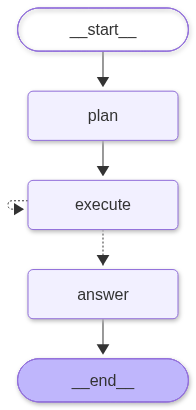

In [10]:
pe_graph